# Week 5 · Probability Foundations and Bayes' Theorem

*DS 207 · Week 5*

This notebook introduces the language of probability (sample spaces, events, and conditional probability) and builds toward Bayes' theorem, the rule for revising a belief when new evidence arrives. Every idea is developed in one setting: the fraud-screening operation at PesoWave Digital Bank, where a model flags suspicious transactions and analysts must decide how far to trust each flag. Each subtopic moves from intuition, to a hand calculation on a small extract, to a full-scale verification in Python, to the decision the result supports.

*EC Corro, built in collaboration with Claude, ChatGPT, and Gemini*

## Learning Objectives

By the end of this notebook you should be able to:

- Define a sample space and events, and apply the complement, addition, and multiplication rules to transaction data.
- Compute and interpret conditional probabilities, and distinguish $P(A \mid B)$ from $P(B \mid A)$.
- Derive Bayes' theorem from the definition of conditional probability and name its parts: prior, likelihood, evidence, and posterior.
- Apply Bayes' theorem, including sequential updating, to estimate the probability that a flagged transaction is genuinely fraudulent.

**Prerequisites:** Weeks 1 to 3 (proportions, contingency tables, descriptive summaries) and basic `pandas` filtering.

## Business Context

PesoWave Digital Bank is a mobile e-wallet and digital bank. Customers use it to send app transfers, pay merchants by QR code, cash in at partner outlets, and pay bills. A fraud-screening model scores every transaction and flags the suspicious ones for review by a small team of fraud analysts. Trina Salvador, Head of Fraud and Risk Operations, must decide how those analysts spend their limited hours and which customer-facing controls, such as a step-up one-time PIN (OTP) challenge, to trigger. The question this week's topic answers is: **when the model flags a transaction, how likely is it to be genuine fraud, and how should that probability change what PesoWave does next?**

The data are a four-week window of 60000 transactions with the following fields.

| Field | Meaning |
|---|---|
| `channel` | App Transfer, QR Merchant Payment, Cash-In, or Bills Payment |
| `amount_band` | Low, Medium, or High value |
| `new_device` | The account was accessed from a device first seen within the past 24 hours |
| `fraud` | Confirmed fraud outcome (determined later by investigation) |
| `flagged` | The fraud-screening model flagged the transaction at the time it occurred |
| `otp_failed` | The customer failed a step-up OTP challenge (challenges are issued to flagged transactions only) |

The model's validation report states a detection rate (sensitivity) of 0.88 and a false-positive rate of 0.04. The cell below builds the window reproducibly.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(207)
N_TXN = 60_000

channels = ["App Transfer", "QR Merchant Payment", "Cash-In", "Bills Payment"]
channel_share = [0.35, 0.30, 0.20, 0.15]
new_device_rate = {"App Transfer": 0.10, "QR Merchant Payment": 0.04,
                   "Cash-In": 0.06, "Bills Payment": 0.05}
base_fraud_rate = {"App Transfer": 0.016, "QR Merchant Payment": 0.006,
                   "Cash-In": 0.003, "Bills Payment": 0.007}
NEW_DEVICE_MULTIPLIER = 6
SENS, FPR = 0.88, 0.04
OTP_FAIL_FRAUD, OTP_FAIL_LEGIT = 0.70, 0.05

channel = rng.choice(channels, size=N_TXN, p=channel_share)
amount_band = rng.choice(["Low", "Medium", "High"], size=N_TXN, p=[0.70, 0.25, 0.05])
new_device = rng.random(N_TXN) < pd.Series(channel).map(new_device_rate).to_numpy()
p_fraud = (pd.Series(channel).map(base_fraud_rate).to_numpy()
           * np.where(new_device, NEW_DEVICE_MULTIPLIER, 1.0))
fraud = rng.random(N_TXN) < p_fraud
flagged = rng.random(N_TXN) < np.where(fraud, SENS, FPR)
otp_draw = rng.random(N_TXN) < np.where(fraud, OTP_FAIL_FRAUD, OTP_FAIL_LEGIT)

df = pd.DataFrame({
    "txn_id": np.arange(1, N_TXN + 1),
    "channel": channel,
    "amount_band": amount_band,
    "new_device": new_device,
    "fraud": fraud,
    "flagged": flagged,
    "otp_failed": flagged & otp_draw,
})

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10})
sns.set_palette("deep")

print(df.shape)
print(f"Confirmed fraud rate: {df['fraud'].mean():.4f}")
df.head()

(60000, 7)
Confirmed fraud rate: 0.0122


,txn_id,channel,amount_band,new_device,fraud,flagged,otp_failed
0,1,App Transfer,Low,False,False,False,False
1,2,QR Merchant Payment,High,False,False,False,False
2,3,Bills Payment,Low,False,False,False,False
3,4,QR Merchant Payment,Medium,False,False,False,False
4,5,Cash-In,Medium,False,False,False,False


## Intuition & Analogy

**Subtopic 1 · Basic Probability Rules**

**Business Hook.** Trina asks: *"How many of our transactions carry at least one risk marker, either a new device or a confirmed fraud outcome? And are those two markers related, or do they overlap only by coincidence?"*

Picture the arrivals hall of Mactan-Cebu International Airport. Every passenger who walks out is one possible outcome, and the whole crowd is the **sample space**. "Arrived from abroad" and "carrying a laptop" are **events**: subsets of that crowd. If an immigration officer wants to know how many people are in *either* group, adding the two head counts double-counts everyone who is in both, so the overlap has to be subtracted once. If she wants the number who are in *neither*, it is easier to count the complement than to enumerate every other case.

The same logic applies to PesoWave's transactions. Pull one transaction at random from the window: the probability that it is fraud is simply the share of the window that is fraud. The harder question is whether two markers are **independent**. Two coin flips do not influence each other; knowing the first tells you nothing about the second. If new devices and fraud travel together, however, learning that a device is new should change what we expect about fraud. Independence is a claim that can be tested against the data.

## Theory — By Hand

**Subtopic 1 · Basic Probability Rules**

The **sample space** $\Omega$ is the set of all possible outcomes. Here, one outcome is one transaction, described by its channel (4 values), amount band (3), device status (2), and fraud outcome (2), so the full description space has $4 \times 3 \times 2 \times 2 = 48$ cells. An **event** is any subset of $\Omega$. Define

- $F$: the transaction is confirmed fraud
- $N$: the transaction came from a new device

Probabilities satisfy $0 \le P(A) \le 1$ and $P(\Omega) = 1$. When all outcomes in a finite sample are equally likely to be drawn, $P(A) = \dfrac{\text{number of outcomes in } A}{\text{number of outcomes in } \Omega}$. Four rules follow:

$$P(A^c) = 1 - P(A) \qquad \text{(complement)}$$

$$P(A \cup B) = P(A) + P(B) - P(A \cap B) \qquad \text{(addition)}$$

$$P(A \cap B) = P(A)\,P(B) \iff A \text{ and } B \text{ are independent}$$

If $A$ and $B$ are *mutually exclusive* ($A \cap B = \varnothing$), the addition rule reduces to $P(A) + P(B)$.

**Worked example.** Take the first 5000 transactions of the window as a small extract. Cross-classifying device status and fraud gives four cell counts:

| | Fraud ($F$) | Not fraud ($F^c$) | Total |
|---|---|---|---|
| New device ($N$) | 19 | 319 | 338 |
| Established device ($N^c$) | 40 | 4622 | 4662 |
| Total | 59 | 4941 | 5000 |

1. Marginal probabilities: $P(F) = \dfrac{59}{5000} = 0.0118$ and $P(N) = \dfrac{338}{5000} = 0.0676$.
2. Intersection: $P(F \cap N) = \dfrac{19}{5000} = 0.0038$.
3. Union by the addition rule: $P(F \cup N) = 0.0118 + 0.0676 - 0.0038 = 0.0756$. Direct count check: $(59 + 338 - 19)/5000 = 378/5000 = 0.0756$.
4. Complement of the union ("neither marker"): $P(F^c \cap N^c) = 1 - 0.0756 = 0.9244$, which matches the direct count $4622/5000 = 0.9244$.
5. Independence test: if $F$ and $N$ were independent, we would expect $P(F)P(N) = 0.0118 \times 0.0676 = 0.000798$. The observed $P(F \cap N) = 0.0038$ is 4.76 times larger, so the two events occur together far more often than chance alone would produce.

## By Tool

**Subtopic 1 · Basic Probability Rules**

The first cell reproduces the by-hand extract. The second scales the same rules to the full window and compares two candidate "marker" pairs: fraud with new device, and fraud with a high-value amount.

In [2]:
# Reproduce the by-hand extract: the first 5,000 transactions
extract = df.head(5000)
print(pd.crosstab(extract["new_device"], extract["fraud"], margins=True))

F_e, N_e = extract["fraud"], extract["new_device"]
p_F, p_N = F_e.mean(), N_e.mean()
p_FN = (F_e & N_e).mean()
p_FuN = (F_e | N_e).mean()

print(f"\nP(F)               = {p_F:.4f}")
print(f"P(N)               = {p_N:.4f}")
print(f"P(F and N)         = {p_FN:.4f}")
print(f"P(F or N), direct  = {p_FuN:.4f}")
print(f"P(F or N), rule    = {p_F + p_N - p_FN:.4f}")
print(f"P(neither)         = {1 - p_FuN:.4f}")
print(f"P(F)P(N)           = {p_F * p_N:.6f}  vs  P(F and N) = {p_FN:.6f}  ->  ratio {p_FN / (p_F * p_N):.2f}")

fraud       False  True   All
new_device                   
False        4622    40  4662
True          319    19   338
All          4941    59  5000

P(F)               = 0.0118
P(N)               = 0.0676
P(F and N)         = 0.0038
P(F or N), direct  = 0.0756
P(F or N), rule    = 0.0756
P(neither)         = 0.9244
P(F)P(N)           = 0.000798  vs  P(F and N) = 0.003800  ->  ratio 4.76


                       P(A)     P(B)  P(A and B)  P(A)P(B)  P(A or B)  addition rule    ratio
pair                                                                                         
Fraud & New device  0.01217  0.06722     0.00445   0.00082    0.07493        0.07493  5.44141
Fraud & High value  0.01217  0.04923     0.00055   0.00060    0.06085        0.06085  0.91819


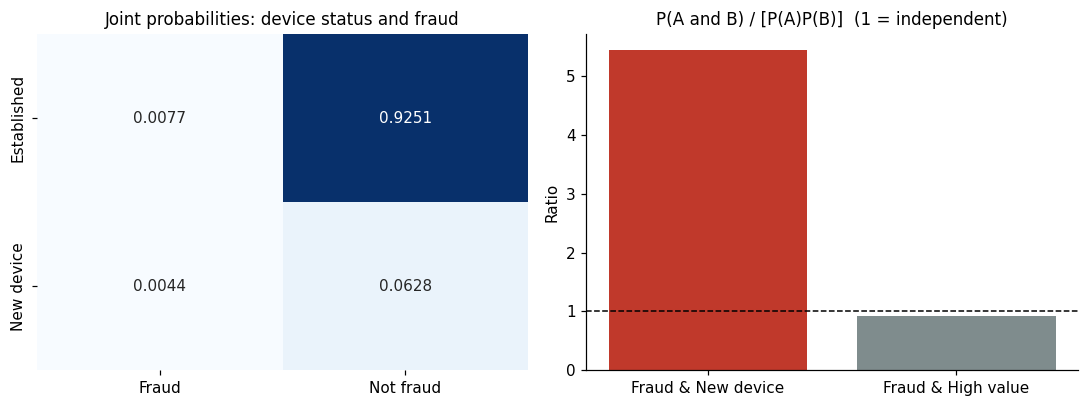

In [3]:
# Full window: addition rule and independence check for two event pairs
F = df["fraud"]
N = df["new_device"]
H = df["amount_band"].eq("High")

def pair_summary(A, B, label):
    p_A, p_B, p_AB = A.mean(), B.mean(), (A & B).mean()
    return {"pair": label, "P(A)": p_A, "P(B)": p_B, "P(A and B)": p_AB,
            "P(A)P(B)": p_A * p_B, "P(A or B)": (A | B).mean(),
            "addition rule": p_A + p_B - p_AB, "ratio": p_AB / (p_A * p_B)}

summary = pd.DataFrame([pair_summary(F, N, "Fraud & New device"),
                        pair_summary(F, H, "Fraud & High value")]).set_index("pair")
print(summary.round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

joint = pd.crosstab(N.map({True: "New device", False: "Established"}),
                    F.map({True: "Fraud", False: "Not fraud"}), normalize=True)
sns.heatmap(joint, annot=True, fmt=".4f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Joint probabilities: device status and fraud")
axes[0].set_xlabel(""); axes[0].set_ylabel("")

axes[1].bar(summary.index, summary["ratio"], color=["#c0392b", "#7f8c8d"])
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_title("P(A and B) / [P(A)P(B)]  (1 = independent)")
axes[1].set_ylabel("Ratio")
plt.tight_layout()
plt.show()

## Business Application

**Subtopic 1 · Basic Probability Rules**

Across the full window, $P(F) = 1.22%$ and $P(N) = 6.72%$, and the union rule shows that 7.49% of transactions carry at least one of the two markers. The informative result is the independence check: fraud and new-device activity co-occur 5.44 times more often than independence would predict, while fraud and high-value amounts sit at a ratio of 0.92, close to 1, so within this window amount band does not add information about fraud on its own.

Trina can therefore treat "new device" as a genuine risk signal worth building controls around, and avoid spending analyst effort on a blanket high-value rule that the data do not support. The next subtopic quantifies how much risk a new device actually carries.

## Intuition & Analogy

**Subtopic 2 · Conditional Probability**

**Business Hook.** The weekly fraud report states that *"36.6% of confirmed fraud cases involved a new device."* Trina asks: *"Does that mean a transaction from a new device has a 36.6% chance of being fraud? If not, what is the number I should be quoting?"*

On a humid afternoon in Cebu City, nearly every rainstorm is preceded by dark clouds: $P(\text{clouds} \mid \text{rain})$ is close to 1. Yet most cloudy afternoons pass without a drop: $P(\text{rain} \mid \text{clouds})$ is far smaller. The two statements sound alike and answer different questions. The first starts from the rainy days and asks how many were cloudy; the second starts from the cloudy days and asks how many turned rainy.

Conditioning means **shrinking the universe**. "Given a new device" tells us to ignore every established-device transaction and look only at what remains. The denominator changes with the question, and most mistakes with conditional probability come from forgetting which group the denominator counts.

## Theory — By Hand

**Subtopic 2 · Conditional Probability**

The probability of $A$ given $B$ is

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}, \qquad P(B) > 0,$$

and rearranging gives the **multiplication rule** $P(A \cap B) = P(A \mid B)\,P(B)$. If $A$ and $B$ are independent, then $P(A \mid B) = P(A)$: the condition carries no information.

**Worked example** on the same 5000-transaction extract (counts: $F \cap N = 19$, $F \cap N^c = 40$, $N$ total $= 338$, $N^c$ total $= 4662$, $F$ total $= 59$):

1. Fraud given new device: $P(F \mid N) = \dfrac{P(F \cap N)}{P(N)} = \dfrac{19}{338} = 0.0562$, or 5.62%.
2. New device given fraud (the transposed question): $P(N \mid F) = \dfrac{19}{59} = 0.3220$, or 32.2%.
3. Fraud given established device: $P(F \mid N^c) = \dfrac{40}{4662} = 0.0086$, or 0.86%.
4. Compare with the base rate $P(F) = 0.0118$: a new device raises the fraud probability by a factor of $0.0562 / 0.0118 \approx 4.76$.

**Common misinterpretations**

- *Transposing the condition.* $P(F \mid N) \ne P(N \mid F)$. Here 5.62% versus 32.2%. The weekly report quotes the second number; the question Trina cares about is the first.
- *Expecting conditionals to sum to one across conditions.* $P(F \mid N) + P(F \mid N^c) = 0.0562 + 0.0086 = 0.0648$, not 1. Only conditionals on the *same* condition sum to one: $P(F \mid N) + P(F^c \mid N) = 1$.
- *Confusing a conditional with a joint probability.* $P(F \cap N) = 0.0038$ is a share of all transactions; $P(F \mid N) = 0.0562$ is a share of new-device transactions only.
- *Reading conditioning as causation.* A new device is associated with higher fraud risk; the calculation does not say the device causes fraud.

## By Tool

**Subtopic 2 · Conditional Probability**

The first cell reproduces the extract calculations; the second computes the same conditionals on the full window and breaks fraud risk down by channel.

In [4]:
# Extract-level conditionals (first 5,000 transactions)
F_e, N_e = extract["fraud"], extract["new_device"]
print(f"P(F | N)     = {F_e[N_e].mean():.4f}")
print(f"P(N | F)     = {N_e[F_e].mean():.4f}")
print(f"P(F | not N) = {F_e[~N_e].mean():.4f}")
print(f"P(F | N) + P(F | not N) = {F_e[N_e].mean() + F_e[~N_e].mean():.4f}   (not 1)")
print(f"P(F | N) + P(not F | N) = {F_e[N_e].mean() + (~F_e[N_e]).mean():.4f}   (always 1)")

P(F | N)     = 0.0562


P(N | F)     = 0.3220
P(F | not N) = 0.0086
P(F | N) + P(F | not N) = 0.0648   (not 1)
P(F | N) + P(not F | N) = 1.0000   (always 1)


P(F)         = 0.0122
P(F | N)     = 0.0662   <- the question Trina cares about
P(N | F)     = 0.3658   <- what the weekly report quotes
P(F | not N) = 0.0083
channel
App Transfer           0.0228
Bills Payment          0.0083
QR Merchant Payment    0.0073
Cash-In                0.0038
Name: fraud, dtype: float64


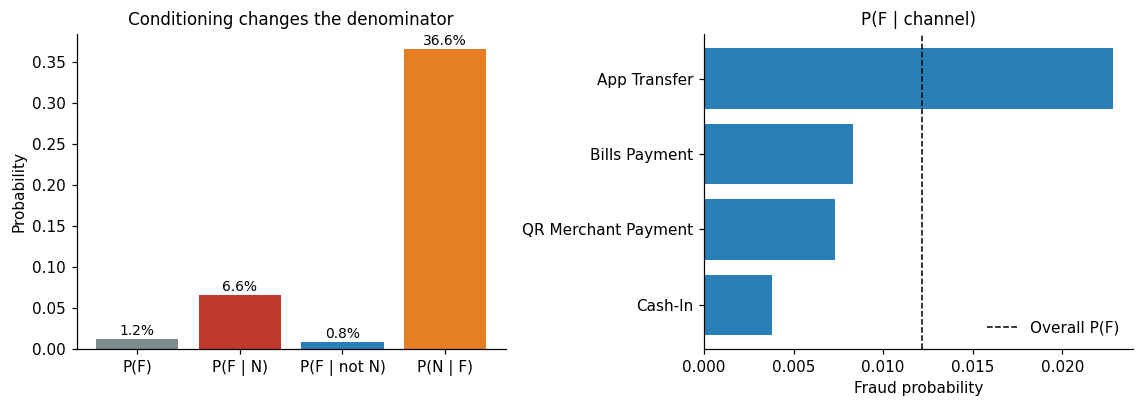

In [5]:
# Full window: the two "alike-sounding" conditionals and fraud rate by channel
P_F = F.mean()
P_F_given_N = F[N].mean()
P_N_given_F = N[F].mean()
P_F_given_notN = F[~N].mean()

print(f"P(F)         = {P_F:.4f}")
print(f"P(F | N)     = {P_F_given_N:.4f}   <- the question Trina cares about")
print(f"P(N | F)     = {P_N_given_F:.4f}   <- what the weekly report quotes")
print(f"P(F | not N) = {P_F_given_notN:.4f}")

by_channel = df.groupby("channel")["fraud"].mean().sort_values(ascending=False)
print(by_channel.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))

labels = ["P(F)", "P(F | N)", "P(F | not N)", "P(N | F)"]
values = [P_F, P_F_given_N, P_F_given_notN, P_N_given_F]
colors = ["#7f8c8d", "#c0392b", "#2980b9", "#e67e22"]
axes[0].bar(labels, values, color=colors)
for i, v in enumerate(values):
    axes[0].text(i, v + 0.005, f"{v:.1%}", ha="center", fontsize=9)
axes[0].set_title("Conditioning changes the denominator")
axes[0].set_ylabel("Probability")

axes[1].barh(by_channel.index[::-1], by_channel.values[::-1], color="#2980b9")
axes[1].axvline(P_F, color="black", linestyle="--", linewidth=1, label="Overall P(F)")
axes[1].set_title("P(F | channel)")
axes[1].set_xlabel("Fraud probability")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## Business Application

**Subtopic 2 · Conditional Probability**

On the full window, $P(N \mid F) = 36.6%$ but $P(F \mid N) = 6.62%$, against 0.83% for established devices: a new device multiplies fraud risk by about 5.4 relative to the overall rate. Trina should retire the "36.6% of fraud involves new devices" line from the weekly report, which describes the composition of fraud cases, and replace it with the conditional fraud rates, which describe the risk a given transaction carries.

The stakeholder action is a control decision: a step-up OTP challenge on new-device transactions targets a group where roughly 1 in 15 transactions is fraudulent, while the same challenge applied to established devices would interrupt more than 100 legitimate customers for every fraud it could stop. Fraud risk also varies by channel, with App Transfer well above the others, so the conditional view supports channel-specific rules rather than a single threshold.

## Intuition & Analogy

**Subtopic 3 · Bayes' Theorem**

**Business Hook.** The model catches 88% of frauds and wrongly flags only 4% of legitimate transactions. Trina asks: *"When an analyst opens a flagged case, what is the chance it is genuine fraud?"* Most people expect an answer near 88%.

Consider a smoke alarm in a kitchen that sounds every time someone makes toast. The alarm is excellent at its job: it rings in almost every real fire. But real fires are rare and toast is common, so when it rings, the likeliest explanation is breakfast. The reliability of the alarm (how often it rings *given* a fire) is a different quantity from the trustworthiness of a ring (how often there is a fire *given* a ring). Bridging the two requires knowing how common fires are to begin with.

That is the structure of Bayes' theorem. A **prior** belief (how common fraud is) is combined with a **likelihood** (how the model behaves on fraud and on legitimate activity) to produce a **posterior** belief (how likely fraud is *after* seeing the flag). Rare events with imperfect detectors produce flags that are mostly false alarms, even when the detector is good.

## Theory — By Hand

**Subtopic 3 · Bayes' Theorem**

**Derivation.** The intersection of two events can be written in two ways using the multiplication rule:

$$P(A \cap B) = P(A \mid B)\,P(B) = P(B \mid A)\,P(A).$$

Dividing both sides by $P(B)$ gives **Bayes' theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}.$$

The denominator, the overall probability of seeing the evidence, comes from the **law of total probability**, which splits $B$ across $A$ and $A^c$:

$$P(B) = P(B \mid A)\,P(A) + P(B \mid A^c)\,P(A^c).$$

Let $F$ be fraud and $\text{Fl}$ be "flagged by the model". Then

$$\underbrace{P(F \mid \text{Fl})}_{\text{posterior}} = \frac{\overbrace{P(\text{Fl} \mid F)}^{\text{likelihood}} \; \overbrace{P(F)}^{\text{prior}}}{\underbrace{P(\text{Fl} \mid F)\,P(F) + P(\text{Fl} \mid F^c)\,P(F^c)}_{\text{evidence}}}.$$

**Worked example.** Use the validation figures and a prior of 1.2% (the approximate fraud rate in the window): $P(F) = 0.012$, sensitivity $P(\text{Fl} \mid F) = 0.88$, and false-positive rate $P(\text{Fl} \mid F^c) = 0.04$.

1. Flagged and fraud: $0.88 \times 0.012 = 0.01056$.
2. Flagged and legitimate: $0.04 \times 0.988 = 0.03952$.
3. Evidence: $P(\text{Fl}) = 0.01056 + 0.03952 = 0.05008$.
4. Posterior: $P(F \mid \text{Fl}) = \dfrac{0.01056}{0.05008} = 0.2109$, or about 21.1%.

**Natural-frequency check.** Imagine 100,000 transactions. About 1,200 are fraud, and the model flags $0.88 \times 1,200 = 1,056$ of them. Of the 98,800 legitimate transactions it flags $0.04 \times 98,800 = 3,952$. The flagged pool holds $1,056 + 3,952 = 5,008$ cases, of which 1,056 are real: $1,056 / 5,008 \approx 21.1%$. An analyst reviews about 4.7 flagged cases for every fraud found.

**Odds form.** Writing the theorem in odds, posterior odds equal prior odds times the likelihood ratio. Prior odds are $0.012 / 0.988 = 0.01215$ and the likelihood ratio of a flag is $0.88 / 0.04 = 22$, so posterior odds are $0.01215 \times 22 = 0.2672$, and $0.2672 / (1 + 0.2672) = 0.2109$, in agreement.

## By Tool

**Subtopic 3 · Bayes' Theorem**

A reusable posterior function reproduces the hand result and is then checked against the flagged transactions in the data. The figure shows what the flagged pool is made of and how strongly the posterior depends on the prior.

In [6]:
def bayes_posterior(prior, sensitivity, fpr):
    """P(fraud | flagged) from the prior, P(flag | fraud), and P(flag | legitimate)."""
    evidence = sensitivity * prior + fpr * (1 - prior)
    return sensitivity * prior / evidence

# By-hand inputs
print(f"Posterior (prior 1.2%, sens 0.88, FPR 0.04): {bayes_posterior(0.012, 0.88, 0.04):.4f}")

# Empirical check on the full window
emp_sens = df.loc[df["fraud"], "flagged"].mean()
emp_fpr = df.loc[~df["fraud"], "flagged"].mean()
emp_prior = df["fraud"].mean()
emp_ppv = df.loc[df["flagged"], "fraud"].mean()

print(f"\nEmpirical sensitivity       : {emp_sens:.4f}")
print(f"Empirical false-positive rate: {emp_fpr:.4f}")
print(f"Empirical prior P(F)         : {emp_prior:.4f}")
print(f"Bayes posterior from these   : {bayes_posterior(emp_prior, emp_sens, emp_fpr):.4f}")
print(f"Observed share of flags that are fraud: {emp_ppv:.4f}  ({df['flagged'].sum():,} flagged cases)")

Posterior (prior 1.2%, sens 0.88, FPR 0.04): 0.2109

Empirical sensitivity       : 0.9041
Empirical false-positive rate: 0.0405
Empirical prior P(F)         : 0.0122
Bayes posterior from these   : 0.2157
Observed share of flags that are fraud: 0.2157  (3,060 flagged cases)


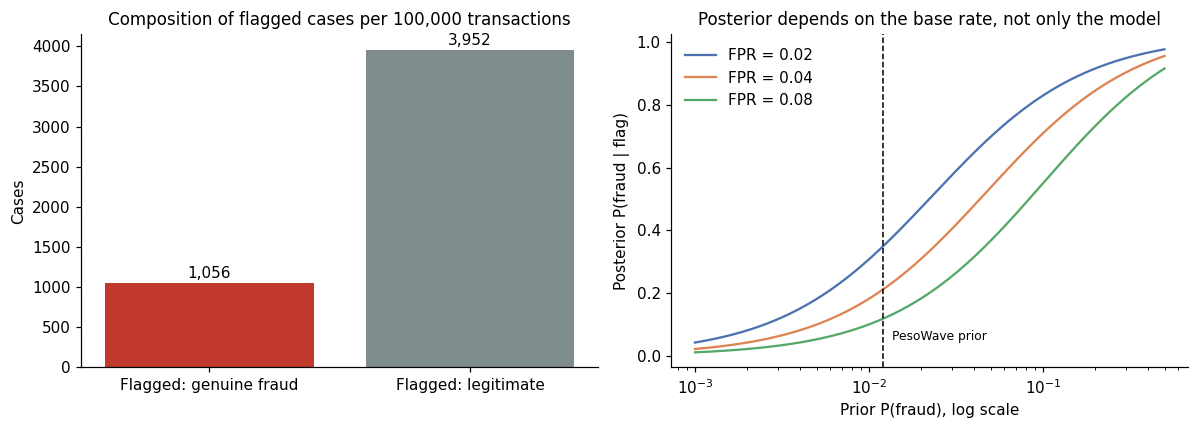

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Composition of the flagged pool per 100,000 transactions
tp = 100_000 * 0.012 * 0.88
fp = 100_000 * 0.988 * 0.04
axes[0].bar(["Flagged: genuine fraud", "Flagged: legitimate"], [tp, fp], color=["#c0392b", "#7f8c8d"])
for i, v in enumerate([tp, fp]):
    axes[0].text(i, v + 60, f"{v:,.0f}", ha="center")
axes[0].set_title("Composition of flagged cases per 100,000 transactions")
axes[0].set_ylabel("Cases")

# Posterior as a function of the prior, for three false-positive rates
priors = np.logspace(-3, np.log10(0.5), 200)
for fpr_val, ls in [(0.02, "-"), (0.04, "-"), (0.08, "-")]:
    axes[1].plot(priors, bayes_posterior(priors, 0.88, fpr_val), linestyle=ls, label=f"FPR = {fpr_val:.2f}")
axes[1].axvline(0.012, color="black", linestyle="--", linewidth=1)
axes[1].text(0.0135, 0.05, "PesoWave prior", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xlabel("Prior P(fraud), log scale")
axes[1].set_ylabel("Posterior P(fraud | flag)")
axes[1].set_title("Posterior depends on the base rate, not only the model")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## Business Application

**Subtopic 3 · Bayes' Theorem**

In the data, 3060 transactions were flagged and 21.6% of them were confirmed fraud, in line with the Bayes calculation of 21.3% from the empirical prior (1.22%), sensitivity (90.4%), and false-positive rate (4.05%). The headline accuracy figures describe the model; the posterior describes what an analyst actually faces. At this prevalence roughly four of every five flagged cases are legitimate customers.

Trina can use this in two ways. First, she can set analyst expectations: a flag is a prompt to investigate, not a verdict, and a team reviewing flags will find about one fraud per 4.7 cases opened. Second, she can see where improvement is worth buying. The right-hand figure shows that halving the false-positive rate lifts the posterior far more than any plausible gain in sensitivity, which is the lever a model-improvement budget should target.

## Intuition & Analogy

**Subtopic 4 · Applying Bayes' Theorem to a Business Question**

**Business Hook.** Trina asks: *"We can review only about half of the flagged cases. How should the queue be ordered, and should the result of the step-up OTP challenge change what an analyst does with a case?"*

A physician does not treat every positive screening result the same way. A positive result in a patient with strong risk factors is far more worrying than the identical result in a low-risk patient, and a second independent test updates the picture again. The first test moves the prior to a posterior; that posterior then becomes the starting point for the next test.

Two ideas combine here. The **prior is segment-specific**: a flag on an App Transfer from a brand-new device starts from a much higher fraud rate than a flag on a QR payment from a long-standing device. And **evidence accumulates**: a failed OTP challenge is strong additional evidence of fraud, while a passed challenge is reassuring but not conclusive.

## Theory — By Hand

**Subtopic 4 · Applying Bayes' Theorem to a Business Question**

**Segment-specific prior.** Replace the overall prior $P(F)$ with the fraud rate of the transaction's segment. From the data, App Transfers from a new device have a fraud rate of 9.76% (use $0.098$), and QR Merchant Payments from an established device have 0.58% (use $0.0058$).

**Sequential updating.** After the flag, the posterior $P(F \mid \text{Fl})$ becomes the new prior for the OTP result $O$. Assuming the two signals are conditionally independent given the fraud status,

$$P(F \mid \text{Fl}, O) = \frac{P(O \mid F)\,P(F \mid \text{Fl})}{P(O \mid F)\,P(F \mid \text{Fl}) + P(O \mid F^c)\,P(F^c \mid \text{Fl})}.$$

The OTP challenge is failed by 70% of fraudulent attempts and 5% of legitimate ones, so $P(\text{fail} \mid F) = 0.70$ and $P(\text{fail} \mid F^c) = 0.05$ (likelihood ratio $14$); passing has likelihoods $0.30$ and $0.95$ (ratio $0.316$).

**Profile X: App Transfer, new device, flagged.**

1. After the flag: numerator $0.88 \times 0.098 = 0.08624$; other term $0.04 \times 0.902 = 0.03608$; posterior $= 0.08624 / (0.08624 + 0.03608) = 0.7050$ (70.5%).
2. OTP failed: $\dfrac{0.70 \times 0.7050}{0.70 \times 0.7050 + 0.05 \times (1 - 0.7050)} = 0.9710$ (97.1%).
3. OTP passed: $\dfrac{0.30 \times 0.7050}{0.30 \times 0.7050 + 0.95 \times (1 - 0.7050)} = 0.4301$ (43.0%).

**Profile Y: QR Merchant Payment, established device, flagged.**

1. After the flag: $0.88 \times 0.0058 = 0.005104$ and $0.04 \times 0.9942 = 0.039768$, so the posterior is $0.1137$ (11.4%).
2. OTP failed: 0.6425 (64.2%).
3. OTP passed: 0.0390 (3.9%).

**Odds cross-check for Profile X.** Prior odds $0.098 / 0.902 = 0.1086$. After the flag, $0.1086 \times 22 = 2.3902$ (probability 0.7050). After a failed OTP, $2.3902 \times 14 = 33.463$ (probability 0.9710). Each piece of evidence simply multiplies the odds by its likelihood ratio.

## By Tool

**Subtopic 4 · Applying Bayes' Theorem to a Business Question**

The first cell builds posteriors for all eight channel-by-device segments and compares them with the observed share of flagged cases that were fraud. The second applies the sequential update and checks it against the data. The third turns the posterior into a queue-ordering rule and measures how many frauds a fixed review capacity catches under three orderings.

                                    n   prior  bayes_post  flags  observed_ppv
channel             new_device                                                
App Transfer        False       18864  0.0145      0.2449    990        0.2515
                    True         2090  0.0976      0.7041    269        0.6877
Bills Payment       False        8323  0.0067      0.1297    355        0.1324
                    True          447  0.0380      0.4652     33        0.4848
Cash-In             False       11360  0.0028      0.0585    517        0.0561
                    True          734  0.0191      0.2996     38        0.3684
QR Merchant Payment False       17420  0.0058      0.1137    799        0.1151
                    True          762  0.0420      0.4909     59        0.4746


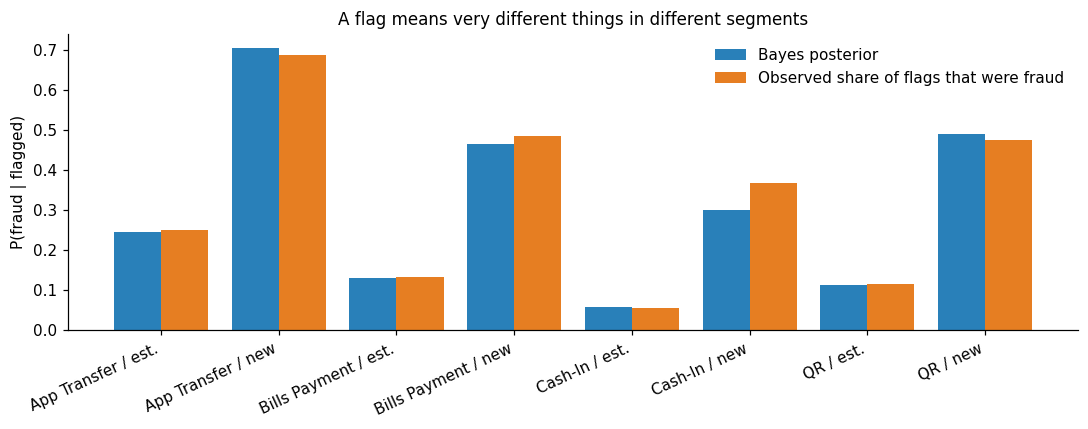

In [8]:
# Segment-level priors and Bayes posteriors after a flag, versus observed fraud share among flags
seg = df.groupby(["channel", "new_device"]).agg(n=("fraud", "size"), prior=("fraud", "mean"))
seg["bayes_post"] = bayes_posterior(seg["prior"], 0.88, 0.04)
flagged_df = df[df["flagged"]]
seg["flags"] = flagged_df.groupby(["channel", "new_device"]).size()
seg["observed_ppv"] = flagged_df.groupby(["channel", "new_device"])["fraud"].mean()
print(seg.round(4).to_string())

plot_df = seg.reset_index()
plot_df["segment"] = plot_df["channel"].str.replace(" Merchant Payment", "") + np.where(plot_df["new_device"], " / new", " / est.")
x = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, plot_df["bayes_post"], width=0.4, label="Bayes posterior", color="#2980b9")
ax.bar(x + 0.2, plot_df["observed_ppv"], width=0.4, label="Observed share of flags that were fraud", color="#e67e22")
ax.set_xticks(x); ax.set_xticklabels(plot_df["segment"], rotation=25, ha="right")
ax.set_ylabel("P(fraud | flagged)")
ax.set_title("A flag means very different things in different segments")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

App Transfer, new device: prior 0.0980 -> flag 0.7050 -> OTP failed 0.9710 | OTP passed 0.4301
QR payment, established device: prior 0.0058 -> flag 0.1137 -> OTP failed 0.6425 | OTP passed 0.0390


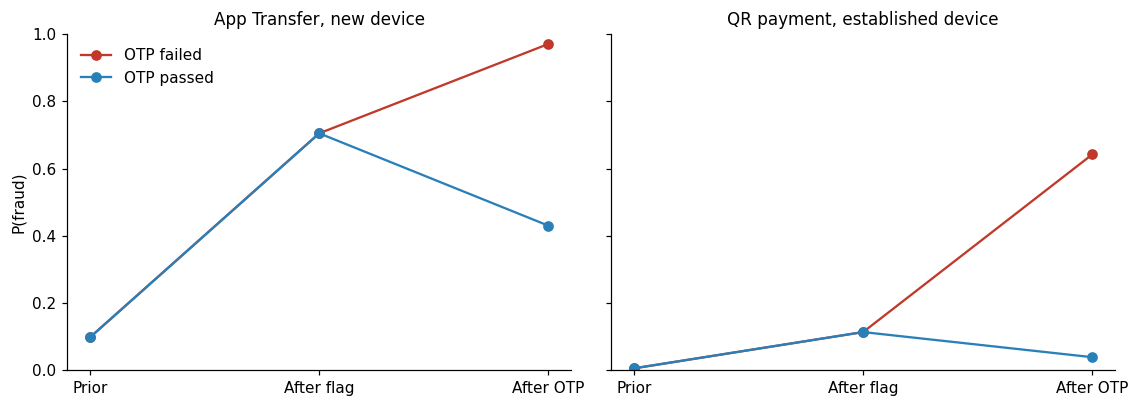


App Transfer, new device: observed fraud share among flagged cases
             mean  size
otp_failed             
OTP passed  0.347   124
OTP failed  0.979   145

QR payment, established device: observed fraud share among flagged cases
             mean  size
otp_failed             
OTP passed  0.032   687
OTP failed  0.625   112


In [9]:
def sequential_update(prior, steps):
    """Apply Bayes' theorem repeatedly. steps is a list of (P(evidence | fraud), P(evidence | legitimate))."""
    path = [prior]
    for lik_f, lik_l in steps:
        path.append(lik_f * path[-1] / (lik_f * path[-1] + lik_l * (1 - path[-1])))
    return path

FLAG = (0.88, 0.04)
OTP_FAIL = (0.70, 0.05)
OTP_PASS = (0.30, 0.95)

profiles = {"App Transfer, new device": 0.098, "QR payment, established device": 0.0058}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, (name, prior) in zip(axes, profiles.items()):
    fail_path = sequential_update(prior, [FLAG, OTP_FAIL])
    pass_path = sequential_update(prior, [FLAG, OTP_PASS])
    print(f"{name}: prior {prior:.4f} -> flag {fail_path[1]:.4f} -> OTP failed {fail_path[2]:.4f} | OTP passed {pass_path[2]:.4f}")
    ax.plot(["Prior", "After flag", "After OTP"], fail_path, marker="o", color="#c0392b", label="OTP failed")
    ax.plot(["Prior", "After flag", "After OTP"], pass_path, marker="o", color="#2980b9", label="OTP passed")
    ax.set_title(name)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("P(fraud)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

# Empirical check among flagged cases in each profile
checks = {"App Transfer, new device": (df["channel"] == "App Transfer") & df["new_device"],
          "QR payment, established device": (df["channel"] == "QR Merchant Payment") & ~df["new_device"]}
for name, mask in checks.items():
    sub = df[mask & df["flagged"]]
    obs = sub.groupby("otp_failed")["fraud"].agg(["mean", "size"]).rename(index={True: "OTP failed", False: "OTP passed"})
    print(f"\n{name}: observed fraud share among flagged cases")
    print(obs.round(3).to_string())

Random order                    : frauds caught with 1,500 reviews = 311 of 660 (47.1%)
Segment posterior (flag only)   : frauds caught with 1,500 reviews = 510 of 660 (77.3%)
Full posterior (flag + OTP)     : frauds caught with 1,500 reviews = 612 of 660 (92.7%)


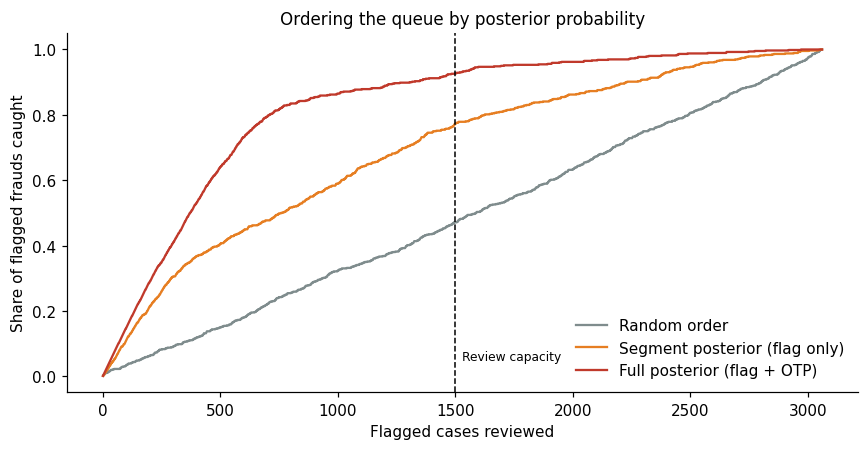

In [10]:
# Queue ordering under a fixed review capacity
review_capacity = 1500

queue = flagged_df.merge(seg[["prior", "bayes_post"]].reset_index(), on=["channel", "new_device"])
queue["full_post"] = np.where(queue["otp_failed"],
                              bayes_posterior(queue["bayes_post"], *OTP_FAIL),
                              bayes_posterior(queue["bayes_post"], *OTP_PASS))

tiebreak = np.random.default_rng(6).random(len(queue))
random_score = np.random.default_rng(5).random(len(queue))
orderings = {"Random order": random_score,
             "Segment posterior (flag only)": queue["bayes_post"].to_numpy(),
             "Full posterior (flag + OTP)": queue["full_post"].to_numpy()}

total_fraud = int(queue["fraud"].sum())
curves = {}
for name, score in orderings.items():
    order = np.lexsort((tiebreak, -score))
    caught = np.cumsum(queue["fraud"].to_numpy()[order])
    curves[name] = caught
    print(f"{name:32s}: frauds caught with {review_capacity:,} reviews = {caught[review_capacity - 1]} of {total_fraud} "
          f"({caught[review_capacity - 1] / total_fraud:.1%})")

fig, ax = plt.subplots(figsize=(8, 4.2))
for (name, caught), color in zip(curves.items(), ["#7f8c8d", "#e67e22", "#c0392b"]):
    ax.plot(np.arange(1, len(caught) + 1), caught / total_fraud, label=name, color=color)
ax.axvline(review_capacity, color="black", linestyle="--", linewidth=1)
ax.text(review_capacity + 30, 0.05, "Review capacity", fontsize=8)
ax.set_xlabel("Flagged cases reviewed")
ax.set_ylabel("Share of flagged frauds caught")
ax.set_title("Ordering the queue by posterior probability")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Business Application

**Subtopic 4 · Applying Bayes' Theorem to a Business Question**

Among the 3060 flagged cases, 660 were fraud. With capacity to open 1500 cases (49% of the queue), a random review order catches 311 frauds (47.1%). Ordering by the segment posterior alone catches 510 (77.3%), and adding the OTP result raises that to 612 (92.7%). The model and the headcount are unchanged; only the order differs.

The OTP result also changes what an analyst should do with an individual case. Among flagged App Transfers from new devices, 97.9% of cases with a failed OTP were fraud (145 cases) versus 34.7% with a passed OTP (124 cases); among flagged QR payments from established devices the corresponding figures are 62.5% and 3.2%. These observed rates track the Bayes posteriors of 97.1%, 43.0%, 64.2%, and 3.9%; the largest gap, in the passed-OTP App Transfer cell, comes from a small group of cases and is of the size sampling variation can produce.

Trina's actions follow directly. Rank the queue by posterior so the highest-probability cases are opened first, treat a failed OTP on a high-prior segment as grounds for an immediate hold, and let a passed OTP on a low-prior segment fall to the end of the queue or release automatically. The conditional-independence assumption behind the sequential update should be re-tested periodically, because if the model flag and the OTP result both respond to the same underlying device signal, multiplying their likelihood ratios would overstate the evidence.

## Key Takeaways

**Subtopic 1 · Basic Probability Rules**

- Sample space = all outcomes; an event is a subset. Complement: $P(A^c) = 1 - P(A)$.
- Addition rule: $P(A \cup B) = P(A) + P(B) - P(A \cap B)$; subtract the overlap once.
- Independence means $P(A \cap B) = P(A)P(B)$; the ratio $P(A \cap B) / [P(A)P(B)]$ tests it (1 = independent).
- New device and fraud are strongly dependent; amount band and fraud are not (in this window).

**Subtopic 2 · Conditional Probability**

- $P(A \mid B) = P(A \cap B) / P(B)$: restrict to $B$, then take the share that is $A$.
- $P(A \mid B) \neq P(B \mid A)$; always check which group the denominator counts.
- Only conditionals on the same condition sum to 1: $P(A \mid B) + P(A^c \mid B) = 1$.
- Conditional probability describes association, not causation.

**Subtopic 3 · Bayes' Theorem**

- $P(A \mid B) = \dfrac{P(B \mid A)P(A)}{P(B \mid A)P(A) + P(B \mid A^c)P(A^c)}$: prior $\times$ likelihood, normalised by evidence.
- Good sensitivity and a low false-positive rate do not guarantee a trustworthy flag when the event is rare.
- Natural frequencies (counts per 100,000) make the base-rate effect visible.
- Odds form: posterior odds = prior odds $\times$ likelihood ratio.

**Subtopic 4 · Applying Bayes' Theorem**

- Use segment-specific priors; the same flag carries different weight in different segments.
- Sequential updating: yesterday's posterior is today's prior, valid under conditional independence of the signals.
- Ordering a fixed-capacity queue by posterior substantially increases the frauds caught.
- Re-test the independence assumption; correlated signals overstate the combined evidence.

## References

Blitzstein, J. K., & Hwang, J. (2019). *Introduction to Probability* (2nd ed.). CRC Press.

Bolton, R. J., & Hand, D. J. (2002). Statistical fraud detection: A review. *Statistical Science, 17*(3), 235-255.

Downey, A. B. (2021). *Think Bayes: Bayesian statistics in Python* (2nd ed.). O'Reilly Media.

Gigerenzer, G., & Hoffrage, U. (1995). How to improve Bayesian reasoning without instruction: Frequency formats. *Psychological Review, 102*(4), 684-704.

Kahneman, D., & Tversky, A. (1973). On the psychology of prediction. *Psychological Review, 80*(4), 237-251.

Ross, S. M. (2019). *A First Course in Probability* (10th ed.). Pearson.

Wasserman, L. (2004). *All of Statistics: A Concise Course in Statistical Inference*. Springer.